## Introducción

Importar paquetes.

In [1]:
import time
from datetime import datetime
import pandas as pd
import re

import torch
import torch.nn as nn
import torch.nn.functional as actF

import torch_geometric.nn as pyg_nn
import torch_geometric.utils as pyg_utils

import networkx as nx
import numpy as np
import torch.optim as optim

import torch_geometric.transforms as T

from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

/home/pedro/miniconda3/envs/envml/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Cargar datos. Considero solamente datos de la subcuenca con punto de cierre en la estación de Florída.

In [2]:
data_folder = "../data/input_data/"
map_data_folder = "../data/input_data/"

df_data_all = pd.read_parquet(map_data_folder+"SLC_MAP_all_data_2011_2022.parquet")
df_data_all = df_data_all.drop(columns=["[Florida (Puente Ruta 5)] Nivel de agua (h) [m]"]) # Drop nivel (= Caudal)
df_data_all

,[Florida (Puente Ruta 5)] Caudal (Q) [m3/s],[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[PAM Station] MAP (P) [mm]
date,,,,,,,,,,
2011-01-01,0.347,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.00
2011-01-02,0.333,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.60
2011-01-03,0.353,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.00
2011-01-04,0.383,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.00
2011-01-05,0.383,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.00
...,...,...,...,...,...,...,...,...,...,...
2022-03-24,0.084,2.5,5.9,74.0,329.9,18.5,23.2,11.8,85.1,3.56
2022-03-25,0.062,1.5,2.8,92.0,239.1,13.9,18.6,11.2,112.2,5.14
2022-03-26,0.057,1.7,2.2,89.0,220.3,17.4,21.7,12.7,113.8,1.14


## Graph definition

### Grafo 5

<img src="notebook_imgs/v4/grafo5.jpg" width="10%">

In [3]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [12]:
# --- (2) Se define la conectividad del grafo ---

edge_index = torch.tensor([
    [1, 2],
    [0, 0]
], dtype=torch.long)
edge_index

tensor([[1, 2],
        [0, 0]])

In [13]:
def IDW_Calc(d, p=2):
    d = np.array(d, dtype=float)
    
    weights = 1 / (d ** p)
    weights /= weights.sum()
    
    return weights

In [ ]:
def calc_weights(func):
    row, col = edge_index

    coords = torch.tensor(coords_list, dtype=torch.float)

    distances = torch.linalg.norm(
        coords[row] - coords[col],
        dim=1
    )

    # ---- Prevent extremely small distances ----
    min_dist = distances.quantile(0.1)  # 10th percentile
    distances = torch.clamp(distances, min=min_dist)

    if func=="IDW":


        # ---- Gaussian weighting ----
        weights = torch.tensor(IDW_Calc(distances), dtype=torch.float32)

    elif func=="dist":

        # Use distances directly as weights
        weights = distances

        # Optional normalization to [0,1]
        weights = (weights - weights.min()) / (
            weights.max() - weights.min()
        )


    elif func=="gauss":

        # ---- Gaussian weighting ----
        sigma = distances.mean()

        weights = torch.exp(
            - (distances ** 2) / (2 * sigma ** 2)
        )

        # Normalize to [0,1]
        weights = (weights - weights.min()) / (
            weights.max() - weights.min()
        )

    else:
        print(f"WRONG FUNC: {func}")
        return 0

    dist_weight = weights.view(-1, 1)


    return dist_weight

In [31]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [32]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [7]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

# Second split: val vs test
# dataset_val, dataset_test = train_test_split(
#     df_data_all,
#     train_size=val_ratio / (1 - train_ratio),
#     shuffle=False
# )
#print(f"N° val samples: {len(dataset_val.index)}")

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [8]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"

df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled

df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [9]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [10]:
import torch
from torch_geometric.data import Data

# Return list of windowed graph data
# In this case: 
# - input_window = "window"
# - output_window = 1

def build_windowed_graphs(
    x_all,                     # [num_nodes, T, num_features]
    edge_index,                # [2, num_edges]
    window,
    target_feature_idx,        # feature to predict
    target_node_idx,           # None → predict for all nodes
    edge_weight=None,          # [num_nodes, num_features]
    use_streamflow_as_input=False
):

    num_nodes, T, num_features = x_all.shape

    data_list = []

    for t in range(T - window):

        # Input window
        x_window = x_all[:, t:t+window, :].clone()  # shape: [num_nodes, window, num_features]

        if not use_streamflow_as_input:
            x_window[:, :, target_feature_idx] = 0 # Don't use target as input (set it to zero)

        # Target timestep
        y_full = x_all[:, t+window, target_feature_idx]  # shape: [num_nodes]
        
        # If: 
        #   target_node_idx = None --> Predict all variables
        #   target_node_idx = idx --> Predict 'idx' variable
        if target_node_idx is not None:
            y = y_full[target_node_idx]  # shape: scalar
        else:
            y = y_full  # shape: [num_nodes]

        data = Data(
            x=x_window,
            edge_index=edge_index,
            edge_weight=edge_weight,
            y=y
        )

        data_list.append(data)

    return data_list

In [14]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=False

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[3, 36, 10], edge_index=[2, 2], y=4.089299181941897e-05, edge_weight=[2, 1])
Length test: 785
Graph test: Data(x=[3, 36, 10], edge_index=[2, 2], y=0.0004632504715118557, edge_weight=[2, 1])


---------------------------------------------------------------------

### GNN Model Definition

In [15]:
import torch
import torch.nn as nn
from torch_geometric.nn import GraphConv
from torch.nn import GRU

class BasicGNN(nn.Module):

    def __init__(self, num_features, gnn_hidden, rnn_hidden, out_channels):
        super().__init__()

        self.gnn_hidden = gnn_hidden
        self.num_features = num_features

        self.gconv1 = GraphConv(num_features, gnn_hidden)
        #self.gconv2 = GraphConv(gnn_hidden, gnn_hidden)

        self.rnn = nn.GRU(
            input_size=gnn_hidden,
            hidden_size=rnn_hidden,
            batch_first=True,
        )

        self.fc = nn.Linear(
            rnn_hidden,
            out_channels
        )

    def forward(self, x, edge_index, edge_weight=None):

        # x:
        # [num_nodes, time_window, features]
        N, T, F = x.shape

        gnn_outputs = []

        # Apply conv layer to each data point independently
        for t in range(T):

            x_t = x[:, t, :]  # [num_nodes, features]

            h_t = self.gconv1(
                x_t,
                edge_index=edge_index,
                edge_weight=edge_weight
            )  # [num_nodes, gnn_hidden]
            h_t = actF.relu(h_t)

            gnn_outputs.append(h_t)

        #print(f"Len out before: {len(gnn_outputs)}")
        #print(f"out before: {gnn_outputs[0].shape}")
        
        # Stack time: [num_nodes, time_window, gnn_hidden]
        h = torch.stack(gnn_outputs, dim=1)
        
        #print(f"h stack: {h.shape}")

        # RNN
        h, _ = self.rnn(h)

        # Take last timestep
        h_last = h[:, -1, :]

        # Prediction
        out = self.fc(h_last)

        #print(f"OUT {out.shape}")

        return out.squeeze()

In [16]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [17]:
from sklearn.metrics import r2_score as nse_metric

def train(model, criterion, optimizer, train_loader, use_weigths):
    model.train()
    total_train_loss = 0

    all_preds_inv = []
    all_targets_inv = []

    for data in train_loader:

        optimizer.zero_grad()  # Clear gradients.

        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
        else:
            out = model(data.x, data.edge_index)  # Perform a single forward pass.

        # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
        target_prediction = out[target_node_idx::num_nodes]

        train_loss = criterion(target_prediction, data.y)  # Compute the loss solely based on the training nodes.

        train_loss.backward()  # Derive gradients.
        optimizer.step()  # Update parameters based on gradients.

        total_train_loss += train_loss.item()

        y_pred = target_prediction.detach().cpu().numpy().reshape(-1, 1)
        y_true = data.y.detach().cpu().numpy().reshape(-1, 1)

        all_preds_inv.append(scalerY.inverse_transform(y_pred))
        all_targets_inv.append(scalerY.inverse_transform(y_true))
    
    all_preds_inv = np.concatenate(all_preds_inv, axis=0).ravel()
    all_targets_inv = np.concatenate(all_targets_inv, axis=0).ravel()

    # Before appending inverse pred for NSE evaluation, make negative predictions zero
    all_preds_inv[all_preds_inv<0] = 0

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_train_loss / len(train_loader)

    return avg_loss, nse

def test(model, criterion, test_loader, use_weigths):
    model.eval()

    total_loss = 0.0

    all_preds_inv = []
    all_targets_inv = []

    with torch.no_grad():
        for data in test_loader:

            if use_weigths:
                out = model(data.x, data.edge_index, data.edge_weight)  # Perform a single forward pass.
            else:
                out = model(data.x, data.edge_index)  # Perform a single forward pass.

            # out: [num_nodes x batch_size, num_features] ---> We want 'Caudal' for Node 'Florida' (slice array by num_nodes)
            target_prediction = out[target_node_idx::num_nodes]

            target_prediction_inv = scalerY.inverse_transform(target_prediction.reshape(-1, 1))
            target_true_inv = scalerY.inverse_transform(data.y.reshape(-1, 1))

            # Loss (e.g., MSELoss)
            loss = criterion(target_prediction, data.y)

            total_loss += loss.item()

            # Before appending inverse pred for NSE evaluation, make negative predictions zero
            target_prediction_inv[target_prediction_inv<0] = 0

            all_preds_inv.append(torch.from_numpy(target_prediction_inv))
            all_targets_inv.append(torch.from_numpy(target_true_inv))

    all_preds_inv = torch.cat(all_preds_inv)

    all_targets_inv = torch.cat(all_targets_inv)

    nse = nse_metric(all_targets_inv, all_preds_inv)

    avg_loss = total_loss / len(test_loader)

    return avg_loss, nse

In [ ]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v4/models/BasicGNN_Arq1_weigths.pth')
else:
    torch.save(model, 'v4/models/BasicGNN_Arq1_noweigths.pth')

Epoch [001/200] | Train Loss: 0.008221 | Train NSE: -3.98 | Test Loss: 0.000603 | Test NSE: -0.10
Epoch [002/200] | Train Loss: 0.001584 | Train NSE: 0.02 | Test Loss: 0.000550 | Test NSE: -0.00
Epoch [003/200] | Train Loss: 0.001446 | Train NSE: 0.10 | Test Loss: 0.000506 | Test NSE: 0.08
Epoch [004/200] | Train Loss: 0.001330 | Train NSE: 0.17 | Test Loss: 0.000470 | Test NSE: 0.14
Epoch [005/200] | Train Loss: 0.001230 | Train NSE: 0.24 | Test Loss: 0.000451 | Test NSE: 0.18
Epoch [006/200] | Train Loss: 0.001146 | Train NSE: 0.29 | Test Loss: 0.000447 | Test NSE: 0.18
Epoch [007/200] | Train Loss: 0.001078 | Train NSE: 0.33 | Test Loss: 0.000455 | Test NSE: 0.17
Epoch [008/200] | Train Loss: 0.001024 | Train NSE: 0.37 | Test Loss: 0.000468 | Test NSE: 0.15
Epoch [009/200] | Train Loss: 0.000981 | Train NSE: 0.40 | Test Loss: 0.000482 | Test NSE: 0.12
Epoch [010/200] | Train Loss: 0.000943 | Train NSE: 0.42 | Test Loss: 0.000492 | Test NSE: 0.10
Epoch [011/200] | Train Loss: 0.00090

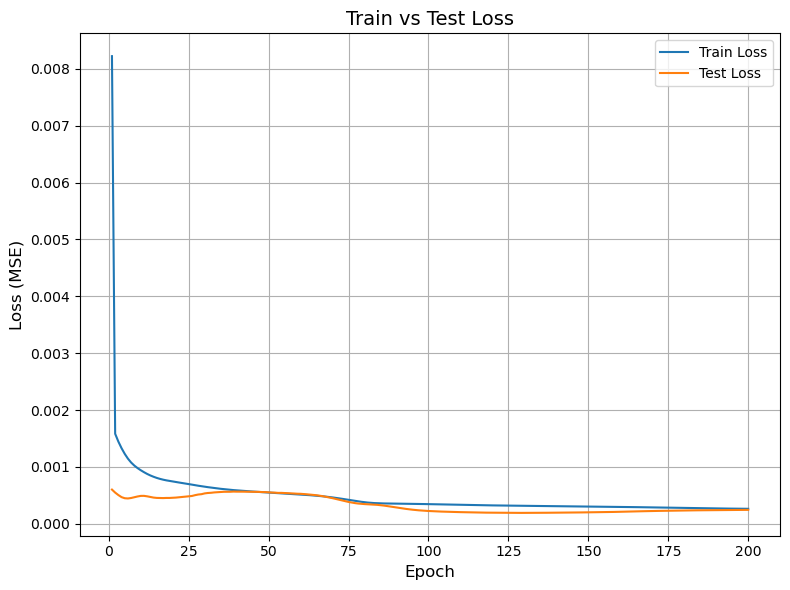

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()

if use_weigths:
    plt.savefig('v4/models/loss_weigths.pth')
else:
    plt.savefig('v4/models/loss_noweigths.pth')
plt.show()

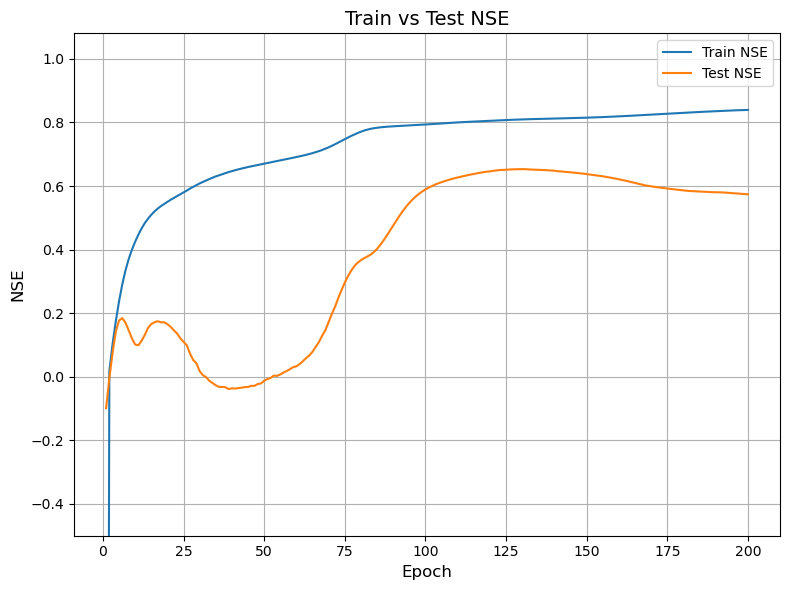

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/nse_weigths.pth')
else:
    plt.savefig('v4/plots/nse_noweigths.pth')
plt.show()

In [ ]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

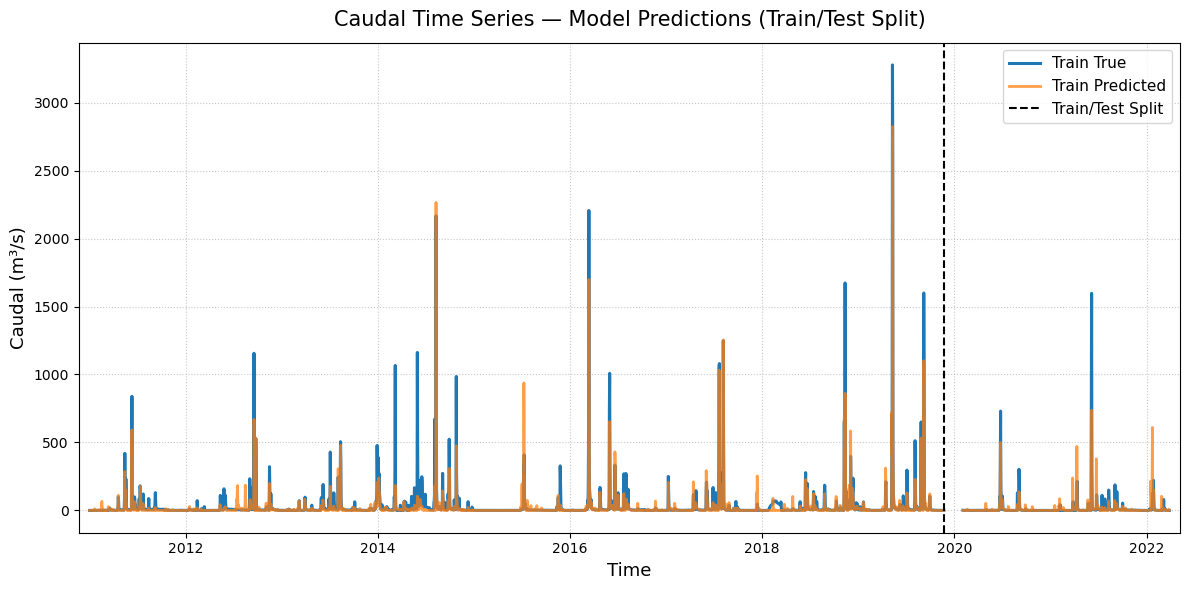

In [ ]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/caudal_weigths.pth')
else:
    plt.savefig('v4/plots/caudal_noweigths.pth')
plt.show()

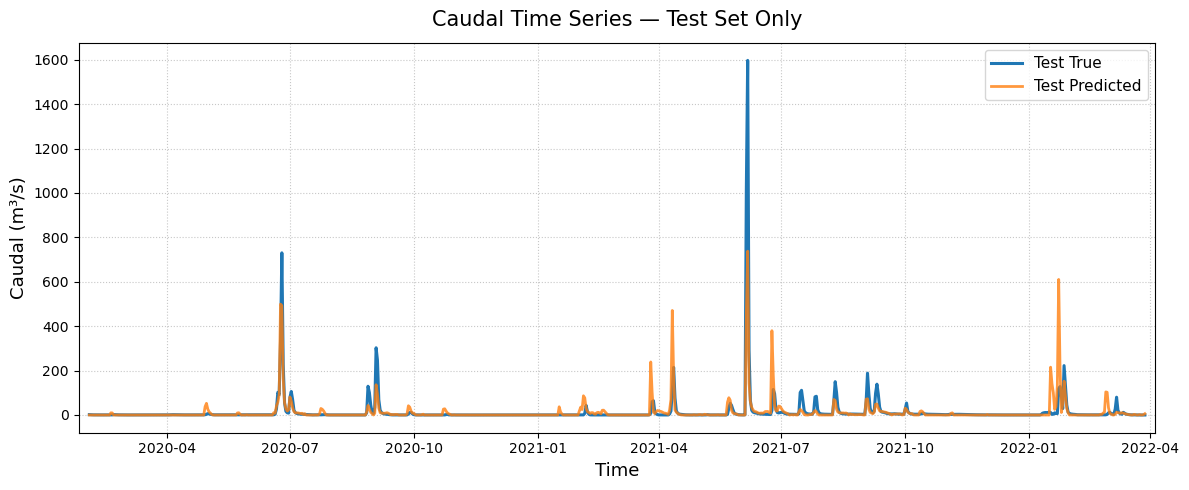

In [ ]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/caudal_test_weigths.pth')
else:
    plt.savefig('v4/plots/caudal_test_noweigths.pth')
plt.show()

-------

## Graph definition

### Grafo 6

<img src="notebook_imgs/v4/grafo6.jpg" width="10%">

In [224]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---
coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [225]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 1, 2],
    [0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 1, 2],
        [0, 0, 0]])

In [226]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [227]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [228]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")

N° train samples: 3284
N° test samples: 821


In [229]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled

df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [230]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [231]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=True

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[3, 36, 10], edge_index=[2, 3], y=4.089299181941897e-05, edge_weight=[3, 1])
Length test: 785
Graph test: Data(x=[3, 36, 10], edge_index=[2, 3], y=0.0004632504715118557, edge_weight=[3, 1])


### GNN Model Definition

In [232]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [242]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v4/models/BasicGNN_grafo6_weigths.pth')
else:
    torch.save(model, 'v4/models/BasicGNN_grafo6_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001566 | Train NSE: 0.04 | Test Loss: 0.000592 | Test NSE: -0.07
Epoch [002/200] | Train Loss: 0.001445 | Train NSE: 0.11 | Test Loss: 0.000571 | Test NSE: -0.03
Epoch [003/200] | Train Loss: 0.001373 | Train NSE: 0.15 | Test Loss: 0.000552 | Test NSE: -0.00
Epoch [004/200] | Train Loss: 0.001312 | Train NSE: 0.19 | Test Loss: 0.000535 | Test NSE: 0.03
Epoch [005/200] | Train Loss: 0.001257 | Train NSE: 0.22 | Test Loss: 0.000516 | Test NSE: 0.06
Epoch [006/200] | Train Loss: 0.001197 | Train NSE: 0.26 | Test Loss: 0.000509 | Test NSE: 0.08
Epoch [007/200] | Train Loss: 0.001156 | Train NSE: 0.28 | Test Loss: 0.000485 | Test NSE: 0.12
Epoch [008/200] | Train Loss: 0.001124 | Train NSE: 0.30 | Test Loss: 0.000469 | Test NSE: 0.15
Epoch [009/200] | Train Loss: 0.001099 | Train NSE: 0.32 | Test Loss: 0.000456 | Test NSE: 0.17
Epoch [010/200] | Train Loss: 0.001077 | Train NSE: 0.33 | Test Loss: 0.000446 | Test NSE: 0.19
Epoch [011/200] | Train Loss: 0.00105

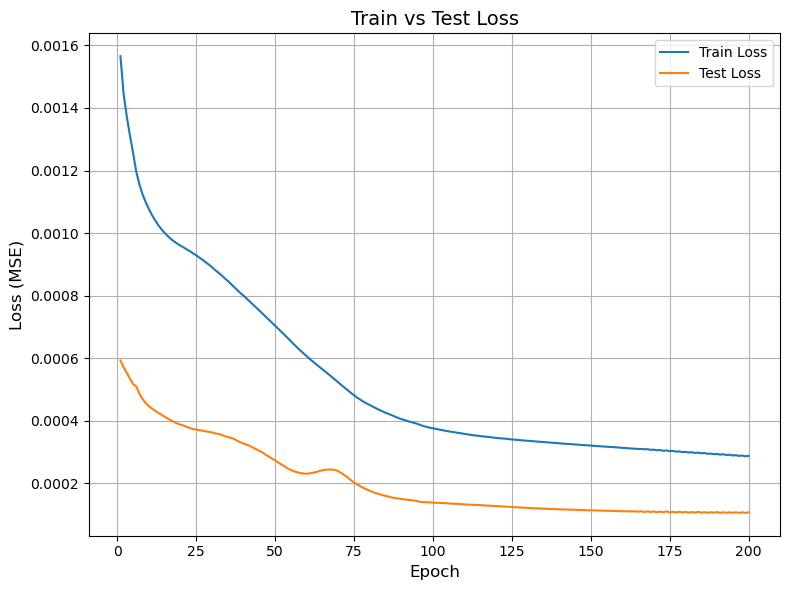

In [243]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo6/loss_weight.png')
else:
    plt.savefig('v4/plots/grafo6/loss_noweight.png')
plt.show()

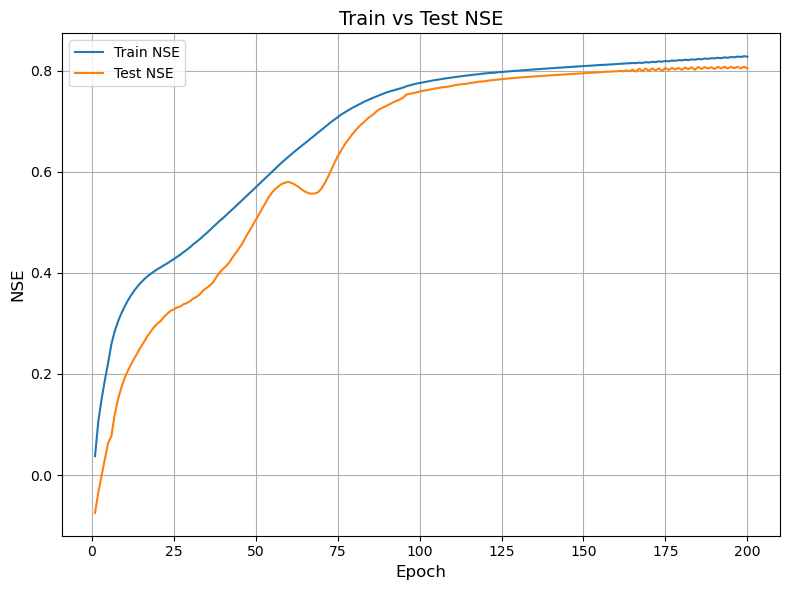

In [244]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo6/nse_weight.png')
else:
    plt.savefig('v4/plots/grafo6/nse_noweight.png')
plt.show()

In [245]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

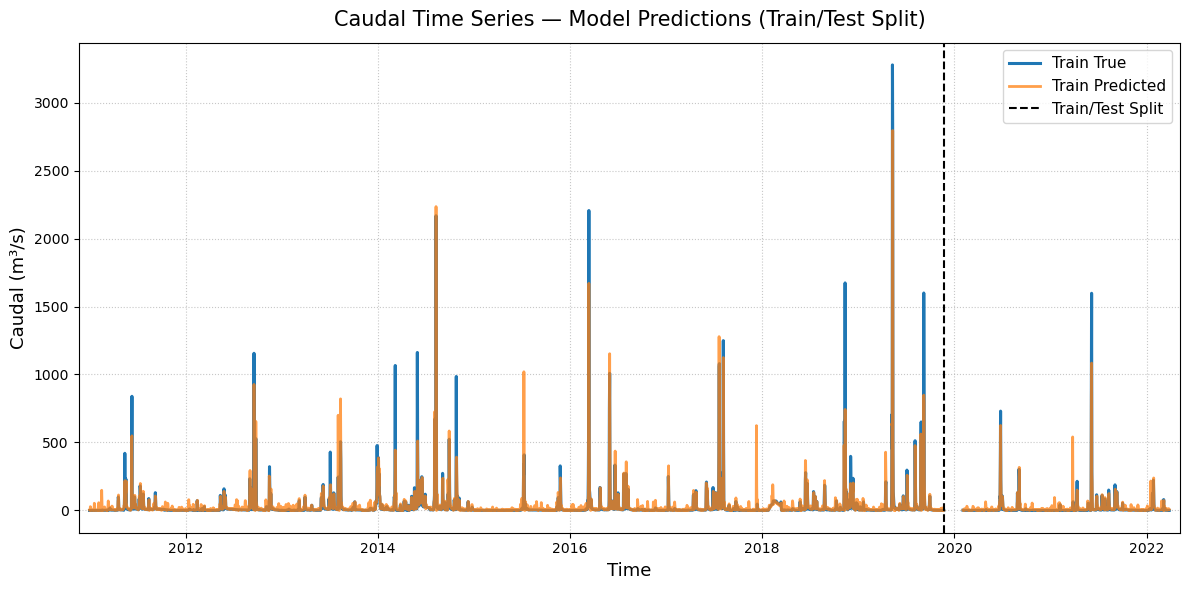

In [246]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo6/caudal_weight.png')
else:
    plt.savefig('v4/plots/grafo6/caudal_noweight.png')
plt.show()

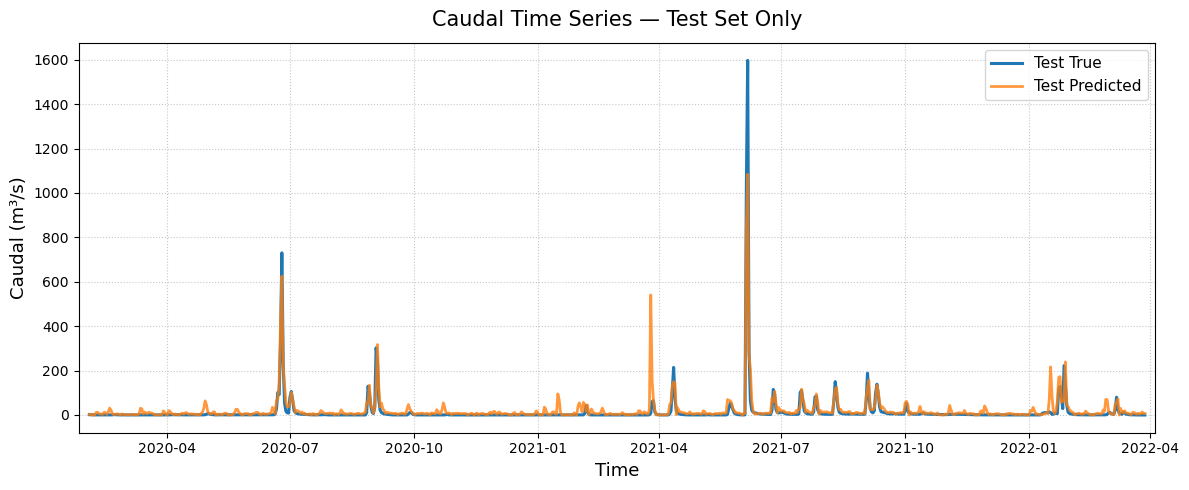

In [247]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo6/caudal_test_weight.png')
else:
    plt.savefig('v4/plots/grafo6/caudal_test_noweight.png')
plt.show()

## Graph Definition

### Grafo 7

<img src="notebook_imgs/v4/grafo7.jpg" width="10%">

In [56]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---

coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [57]:
# --- (2) Se define la conectividad del grafo ---

# Se incorpora un self loop
edge_index = torch.tensor([
    [1, 2],
    [2, 0]
], dtype=torch.long)
edge_index

tensor([[1, 2],
        [2, 0]])

In [58]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [59]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [ ]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [61]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [62]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [63]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=False

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[3, 36, 10], edge_index=[2, 2], y=4.089299181941897e-05, edge_weight=[2, 1])
Length test: 785
Graph test: Data(x=[3, 36, 10], edge_index=[2, 2], y=0.0004632504715118557, edge_weight=[2, 1])


### Modelo

In [65]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [79]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, 'v4/models/BasicGNN_grafo7_weigths.pth')
else:
    torch.save(model, 'v4/models/BasicGNN_grafo7_noweigths.pth')

Epoch [001/200] | Train Loss: 0.004194 | Train NSE: -0.18 | Test Loss: 0.000522 | Test NSE: 0.04
Epoch [002/200] | Train Loss: 0.001502 | Train NSE: 0.07 | Test Loss: 0.000555 | Test NSE: -0.01
Epoch [003/200] | Train Loss: 0.001386 | Train NSE: 0.14 | Test Loss: 0.000527 | Test NSE: 0.04
Epoch [004/200] | Train Loss: 0.001289 | Train NSE: 0.20 | Test Loss: 0.000537 | Test NSE: 0.03
Epoch [005/200] | Train Loss: 0.001208 | Train NSE: 0.25 | Test Loss: 0.000544 | Test NSE: 0.02
Epoch [006/200] | Train Loss: 0.001132 | Train NSE: 0.30 | Test Loss: 0.000546 | Test NSE: 0.01
Epoch [007/200] | Train Loss: 0.001067 | Train NSE: 0.34 | Test Loss: 0.000551 | Test NSE: 0.00
Epoch [008/200] | Train Loss: 0.001016 | Train NSE: 0.38 | Test Loss: 0.000555 | Test NSE: -0.01
Epoch [009/200] | Train Loss: 0.000976 | Train NSE: 0.41 | Test Loss: 0.000561 | Test NSE: -0.02
Epoch [010/200] | Train Loss: 0.000946 | Train NSE: 0.43 | Test Loss: 0.000556 | Test NSE: -0.01
Epoch [011/200] | Train Loss: 0.000

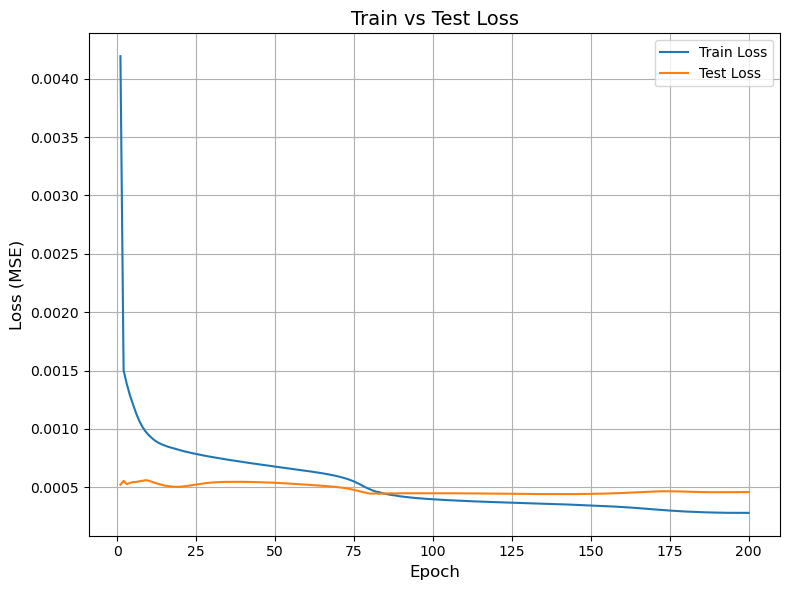

In [80]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo7/loss_weight.png')
else:
    plt.savefig('v4/plots/grafo7/loss_noweight.png')
plt.show()

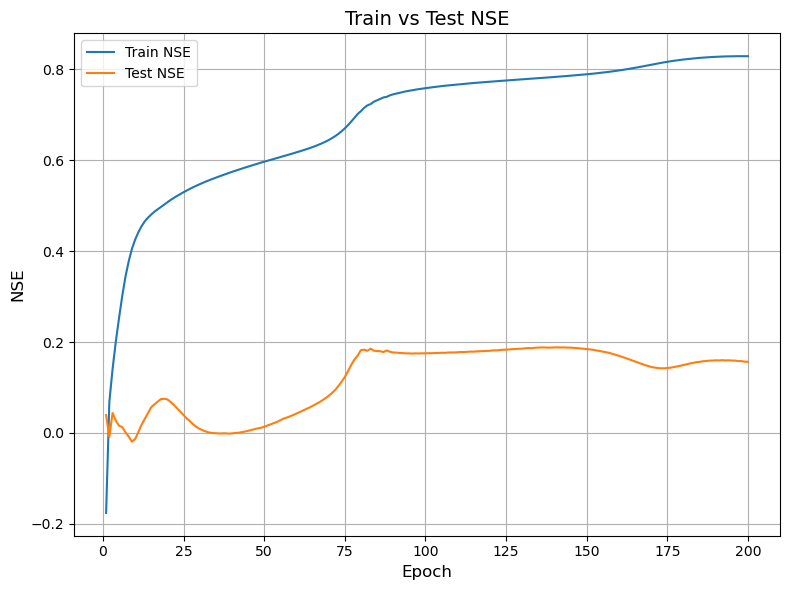

In [81]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo7/nse_weight.png')
else:
    plt.savefig('v4/plots/grafo7/nse_noweight.png')
plt.show()

In [82]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

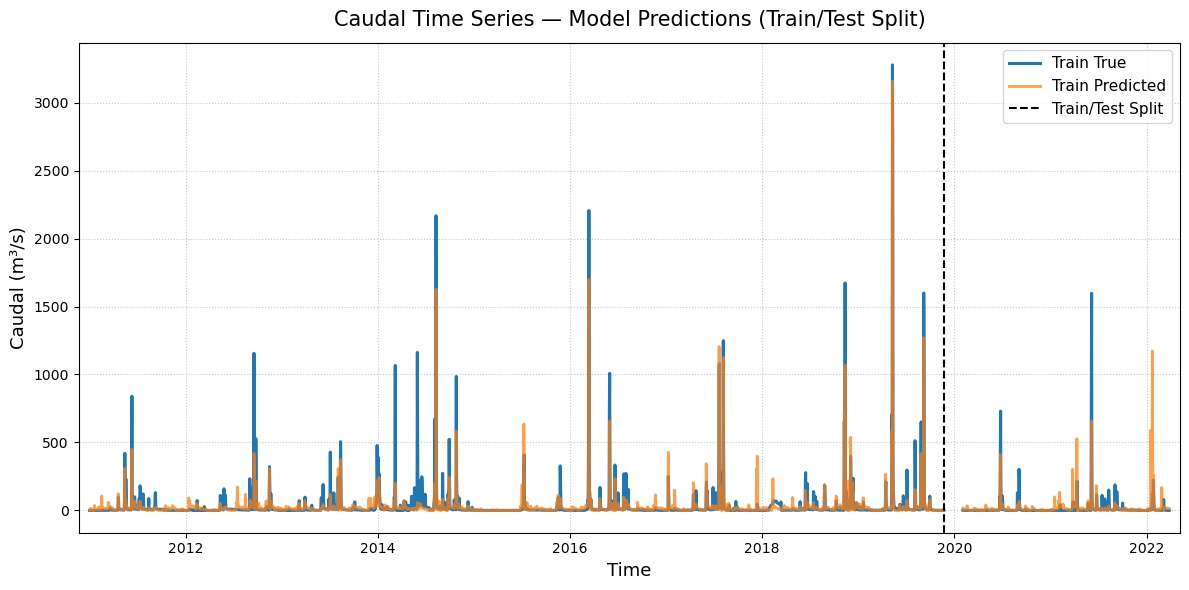

In [83]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo7/caudal_weight.png')
else:
    plt.savefig('v4/plots/grafo7/caudal_noweight.png')
plt.show()

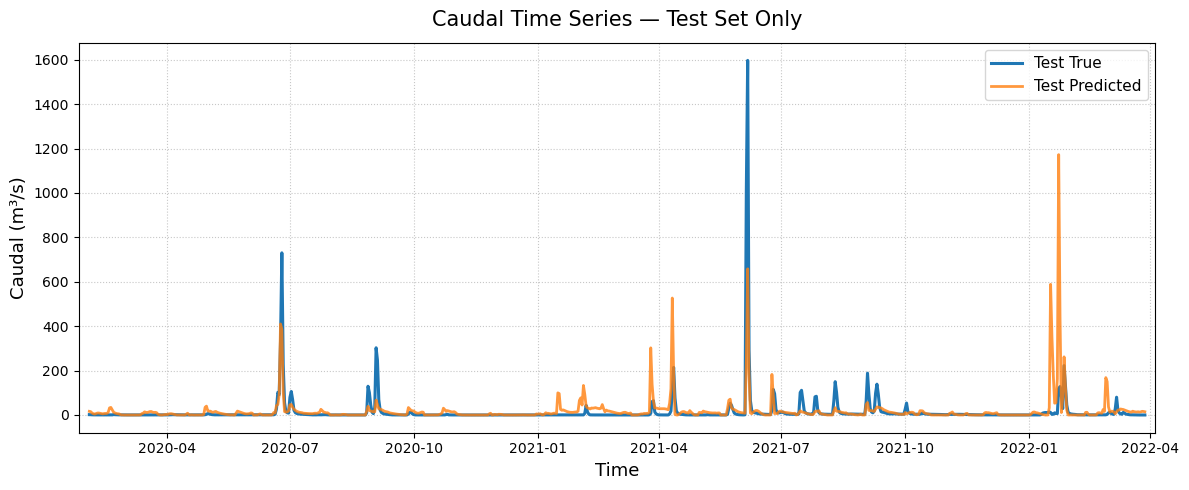

In [84]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig('v4/plots/grafo7/caudal_test_weight.png')
else:
    plt.savefig('v4/plots/grafo7/caudal_test_noweight.png')
plt.show()

## Graph

### Grafo 8

<img src="notebook_imgs/v4/grafo8.jpg" width="10%">

In [85]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---
coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [86]:
# --- (2) Se define la conectividad del grafo ---

num_grafo="grafo8"

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 1, 2],
    [0, 2, 0]
], dtype=torch.long)
edge_index

tensor([[0, 1, 2],
        [0, 2, 0]])

In [87]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [88]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [89]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [90]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [91]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [92]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=True

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[3, 36, 10], edge_index=[2, 3], y=4.089299181941897e-05, edge_weight=[3, 1])
Length test: 785
Graph test: Data(x=[3, 36, 10], edge_index=[2, 3], y=0.0004632504715118557, edge_weight=[3, 1])


### Model

In [93]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [100]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_weigths.pth')
else:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001729 | Train NSE: -0.05 | Test Loss: 0.000653 | Test NSE: -0.18
Epoch [002/200] | Train Loss: 0.001473 | Train NSE: 0.09 | Test Loss: 0.000570 | Test NSE: -0.03
Epoch [003/200] | Train Loss: 0.001269 | Train NSE: 0.22 | Test Loss: 0.000547 | Test NSE: 0.01
Epoch [004/200] | Train Loss: 0.001088 | Train NSE: 0.33 | Test Loss: 0.000567 | Test NSE: -0.02
Epoch [005/200] | Train Loss: 0.000963 | Train NSE: 0.41 | Test Loss: 0.000537 | Test NSE: 0.03
Epoch [006/200] | Train Loss: 0.000904 | Train NSE: 0.45 | Test Loss: 0.000528 | Test NSE: 0.04
Epoch [007/200] | Train Loss: 0.000873 | Train NSE: 0.47 | Test Loss: 0.000521 | Test NSE: 0.05
Epoch [008/200] | Train Loss: 0.000850 | Train NSE: 0.49 | Test Loss: 0.000514 | Test NSE: 0.06
Epoch [009/200] | Train Loss: 0.000831 | Train NSE: 0.50 | Test Loss: 0.000507 | Test NSE: 0.08
Epoch [010/200] | Train Loss: 0.000815 | Train NSE: 0.51 | Test Loss: 0.000501 | Test NSE: 0.09
Epoch [011/200] | Train Loss: 0.0008

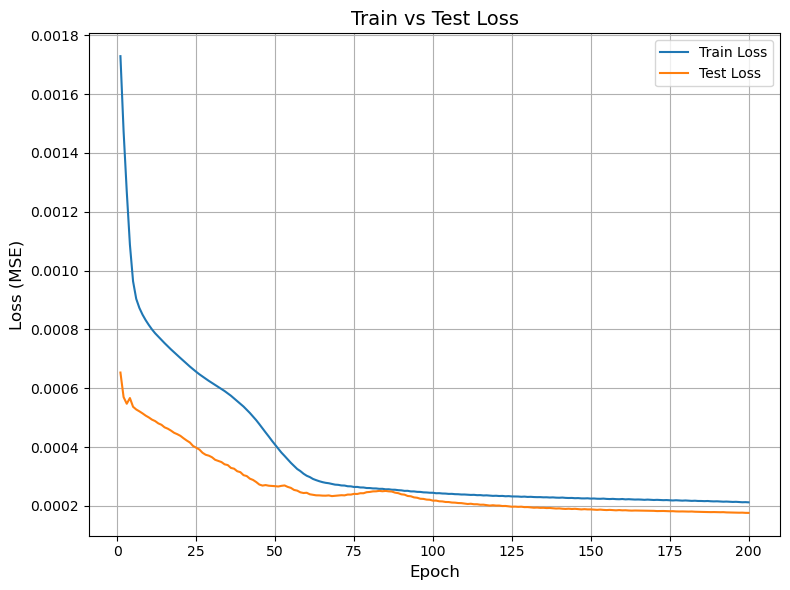

In [101]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/loss_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/loss_noweight.png')
plt.show()

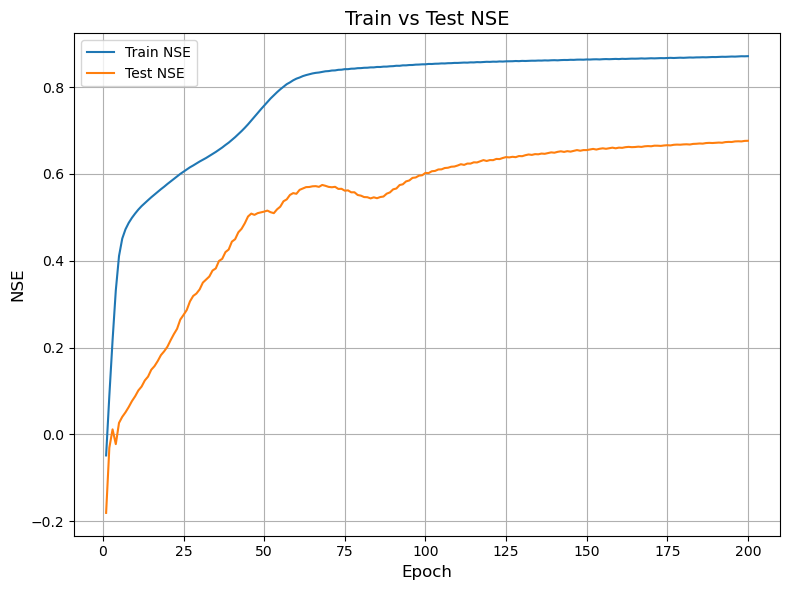

In [102]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/nse_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/nse_noweight.png')
plt.show()

In [103]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

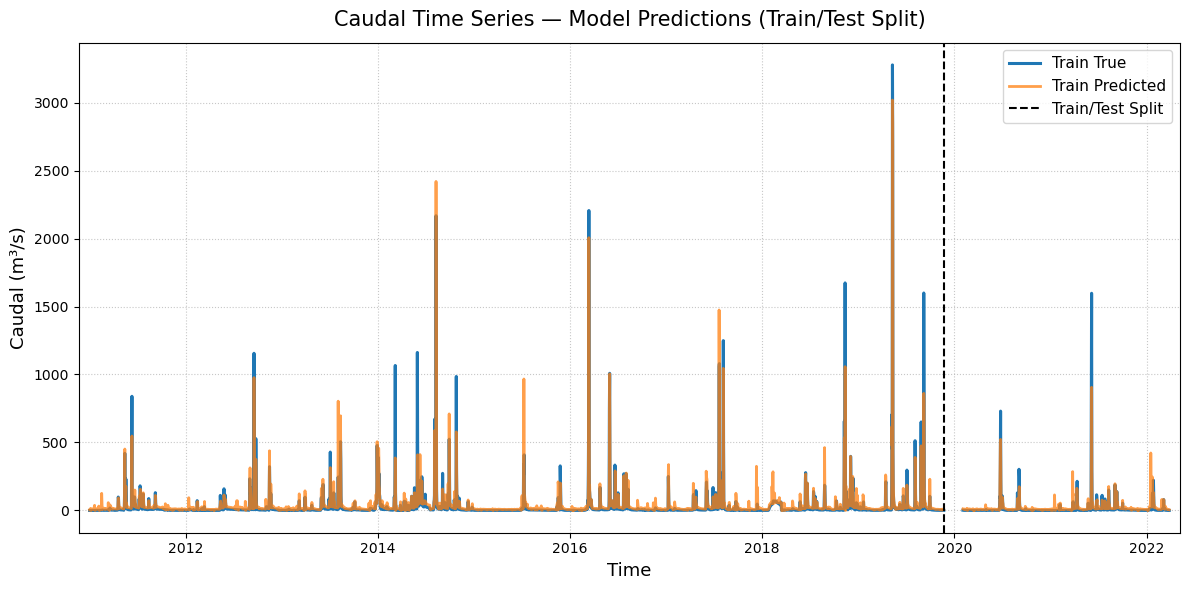

In [104]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_noweight.png')
plt.show()

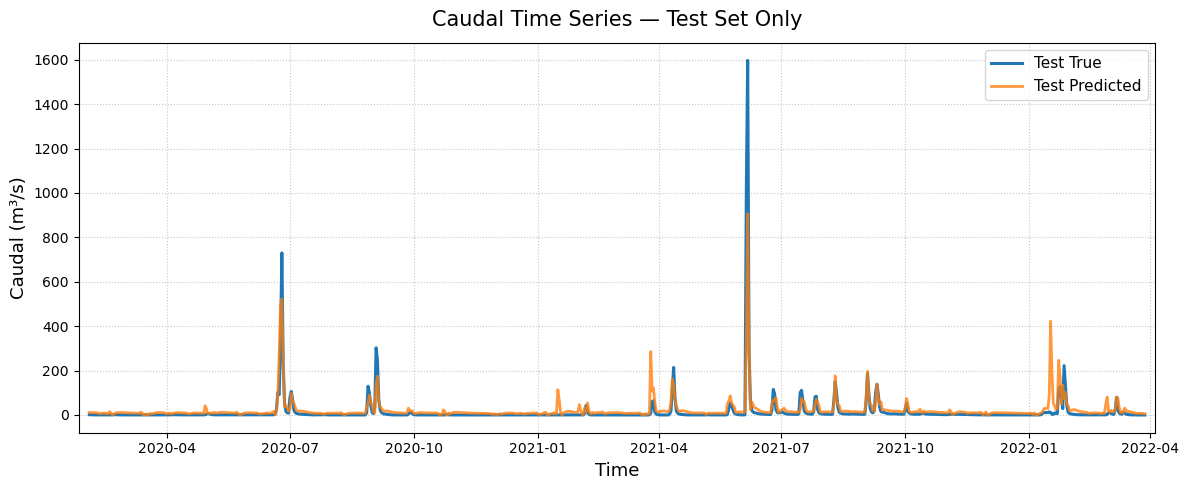

In [105]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_noweight.png')
plt.show()

## Graph

### Grafo 9

<img src="notebook_imgs/v4/grafo9.jpg" width="10%">

In [123]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---
coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [124]:
# --- (2) Se define la conectividad del grafo ---

num_grafo="grafo9"

# Se incorpora un self loop
edge_index = torch.tensor([
    [2],
    [0]
], dtype=torch.long)
edge_index

tensor([[2],
        [0]])

In [125]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [126]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [127]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [128]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [129]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [130]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=False

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[3, 36, 10], edge_index=[2, 1], y=4.089299181941897e-05, edge_weight=[1, 1])
Length test: 785
Graph test: Data(x=[3, 36, 10], edge_index=[2, 1], y=0.0004632504715118557, edge_weight=[1, 1])


### Model

In [131]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [138]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_weigths.pth')
else:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_noweigths.pth')

Epoch [001/200] | Train Loss: 0.003115 | Train NSE: 0.02 | Test Loss: 0.000458 | Test NSE: 0.16
Epoch [002/200] | Train Loss: 0.001243 | Train NSE: 0.23 | Test Loss: 0.000458 | Test NSE: 0.16
Epoch [003/200] | Train Loss: 0.001128 | Train NSE: 0.30 | Test Loss: 0.000483 | Test NSE: 0.12
Epoch [004/200] | Train Loss: 0.001042 | Train NSE: 0.36 | Test Loss: 0.000502 | Test NSE: 0.09
Epoch [005/200] | Train Loss: 0.000975 | Train NSE: 0.40 | Test Loss: 0.000536 | Test NSE: 0.02
Epoch [006/200] | Train Loss: 0.000935 | Train NSE: 0.43 | Test Loss: 0.000546 | Test NSE: 0.00
Epoch [007/200] | Train Loss: 0.000907 | Train NSE: 0.45 | Test Loss: 0.000534 | Test NSE: 0.02
Epoch [008/200] | Train Loss: 0.000883 | Train NSE: 0.46 | Test Loss: 0.000520 | Test NSE: 0.05
Epoch [009/200] | Train Loss: 0.000865 | Train NSE: 0.48 | Test Loss: 0.000510 | Test NSE: 0.06
Epoch [010/200] | Train Loss: 0.000852 | Train NSE: 0.48 | Test Loss: 0.000502 | Test NSE: 0.08
Epoch [011/200] | Train Loss: 0.000841 |

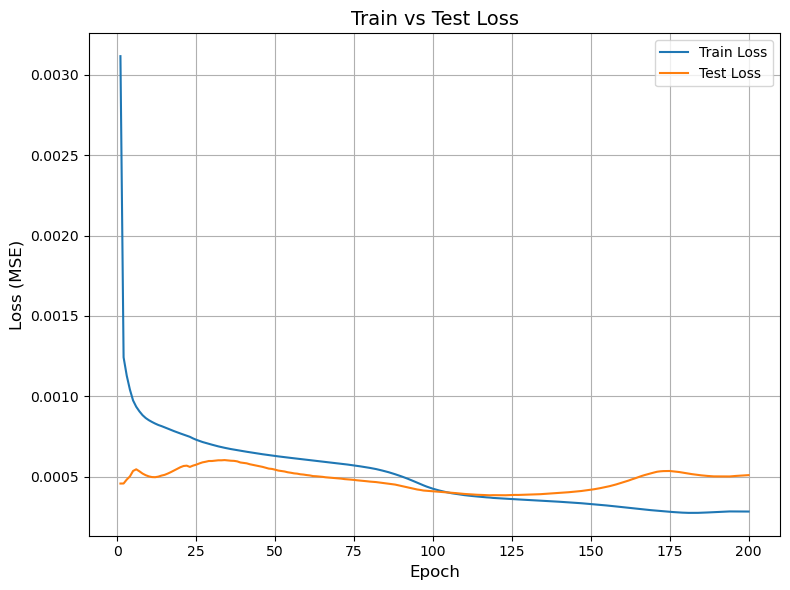

In [139]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/loss_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/loss_noweight.png')
plt.show()

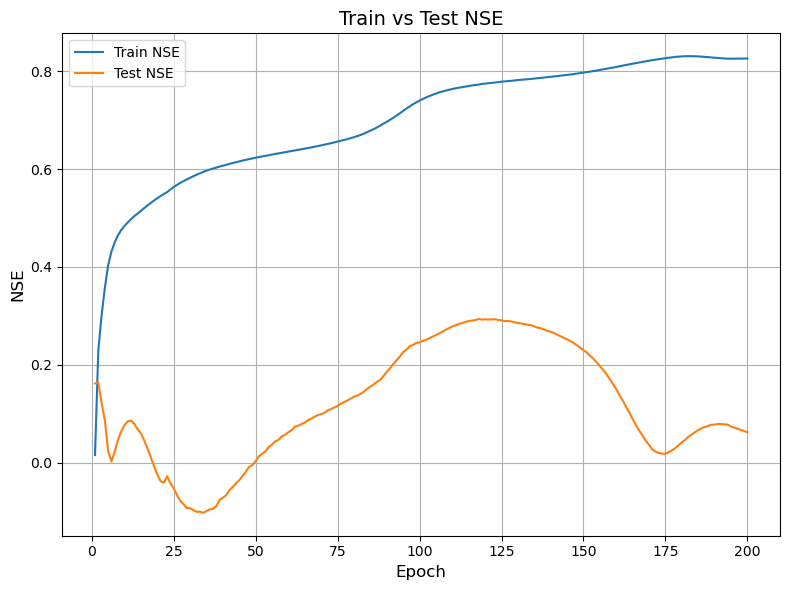

In [140]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/nse_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/nse_noweight.png')
plt.show()

In [141]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

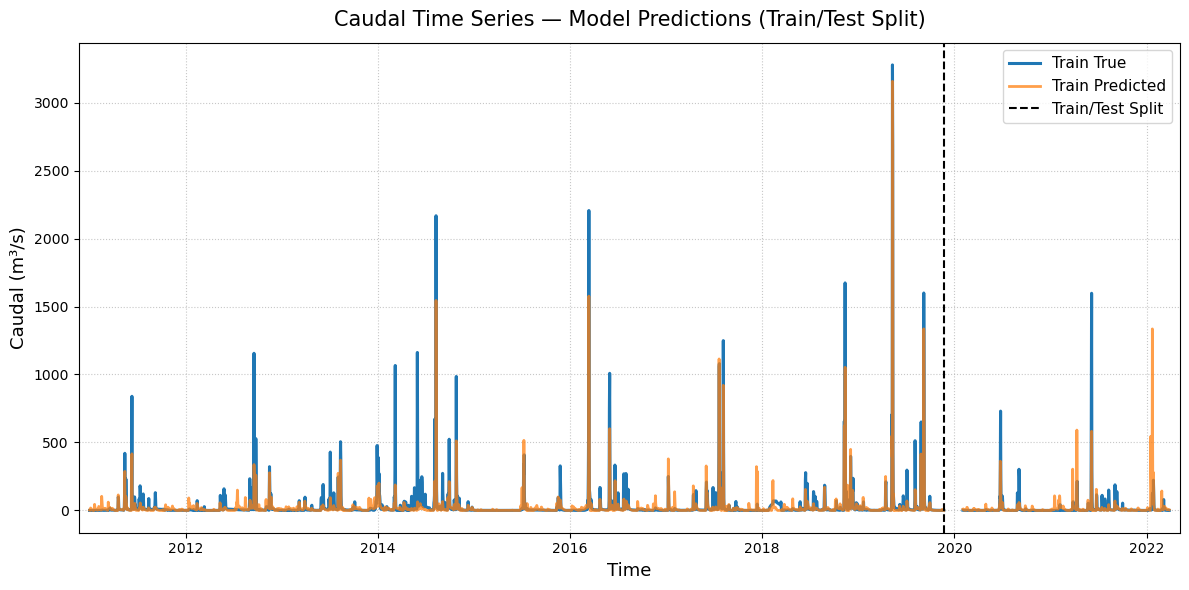

In [142]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_noweight.png')
plt.show()

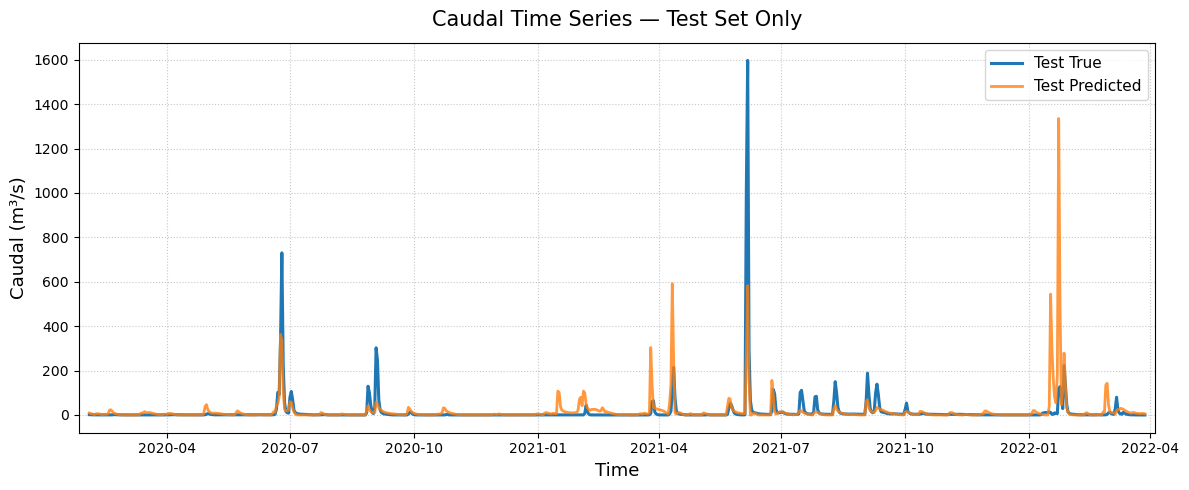

In [143]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_noweight.png')
plt.show()

## Graph

### Grafo 10

<img src="notebook_imgs/v4/grafo10.jpg" width="10%">

In [144]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---
coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [145]:
# --- (2) Se define la conectividad del grafo ---

num_grafo="grafo10"

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 2],
    [0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 2],
        [0, 0]])

In [146]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [147]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [148]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [149]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [150]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [151]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=True

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[3, 36, 10], edge_index=[2, 2], y=4.089299181941897e-05, edge_weight=[2, 1])
Length test: 785
Graph test: Data(x=[3, 36, 10], edge_index=[2, 2], y=0.0004632504715118557, edge_weight=[2, 1])


### Model

In [152]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [160]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_weigths.pth')
else:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_noweigths.pth')

Epoch [001/200] | Train Loss: 0.002329 | Train NSE: 0.01 | Test Loss: 0.000678 | Test NSE: -0.22
Epoch [002/200] | Train Loss: 0.001365 | Train NSE: 0.15 | Test Loss: 0.000596 | Test NSE: -0.07
Epoch [003/200] | Train Loss: 0.001220 | Train NSE: 0.25 | Test Loss: 0.000532 | Test NSE: 0.04
Epoch [004/200] | Train Loss: 0.001079 | Train NSE: 0.33 | Test Loss: 0.000434 | Test NSE: 0.21
Epoch [005/200] | Train Loss: 0.000960 | Train NSE: 0.41 | Test Loss: 0.000395 | Test NSE: 0.28
Epoch [006/200] | Train Loss: 0.000884 | Train NSE: 0.46 | Test Loss: 0.000392 | Test NSE: 0.28
Epoch [007/200] | Train Loss: 0.000840 | Train NSE: 0.49 | Test Loss: 0.000404 | Test NSE: 0.26
Epoch [008/200] | Train Loss: 0.000813 | Train NSE: 0.51 | Test Loss: 0.000420 | Test NSE: 0.23
Epoch [009/200] | Train Loss: 0.000795 | Train NSE: 0.52 | Test Loss: 0.000432 | Test NSE: 0.21
Epoch [010/200] | Train Loss: 0.000782 | Train NSE: 0.53 | Test Loss: 0.000439 | Test NSE: 0.20
Epoch [011/200] | Train Loss: 0.000771

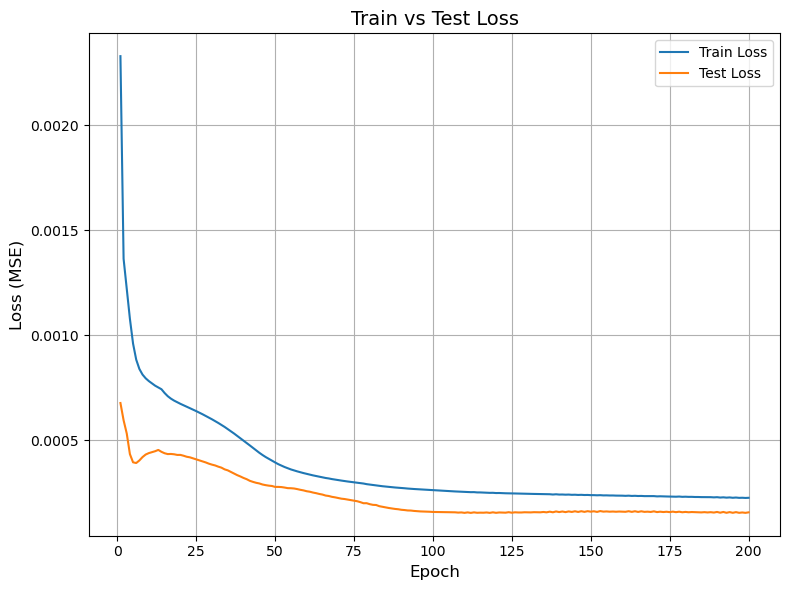

In [161]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/loss_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/loss_noweight.png')
plt.show()

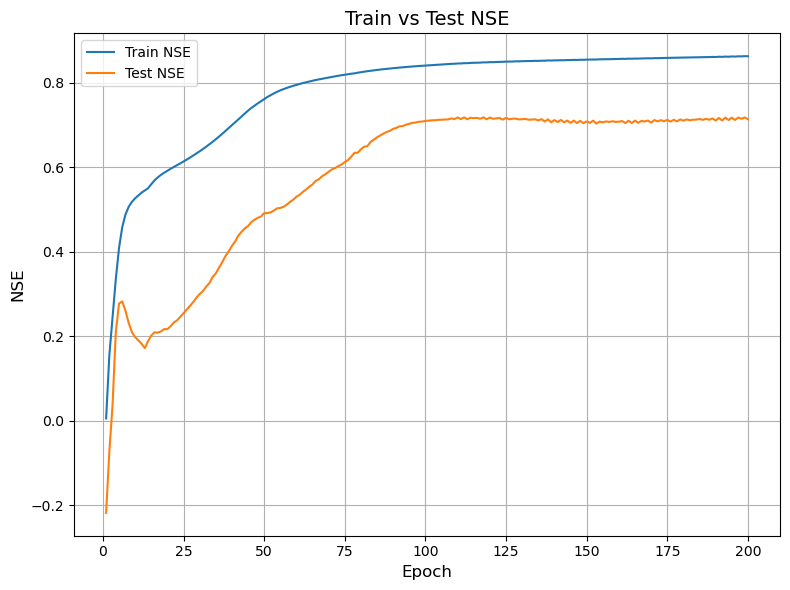

In [162]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/nse_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/nse_noweight.png')
plt.show()

In [163]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

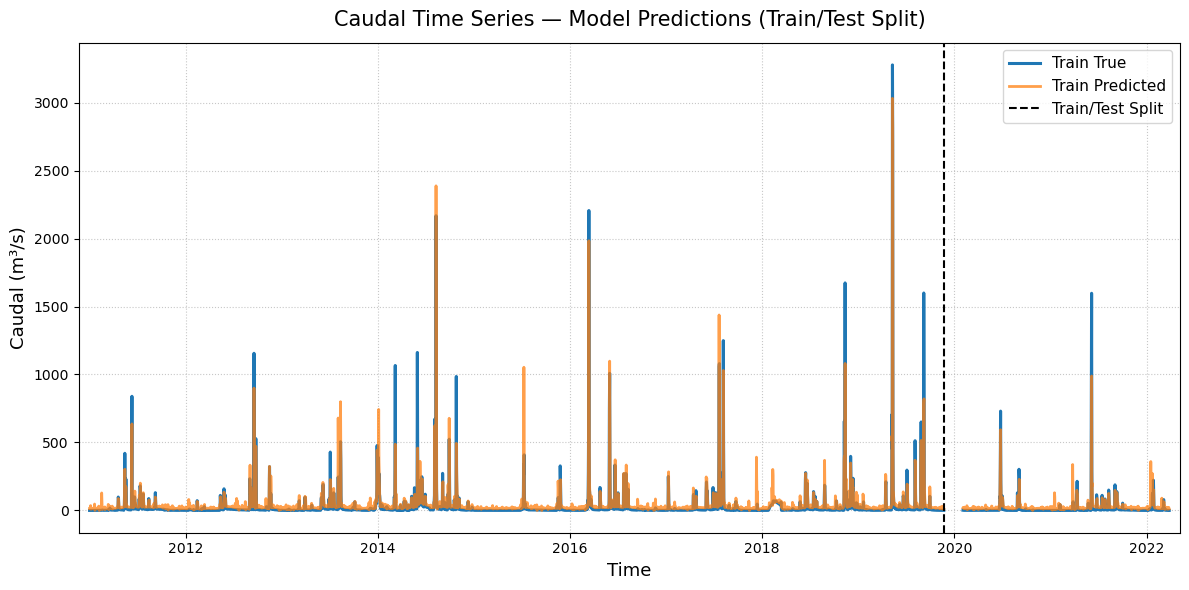

In [164]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_noweight.png')
plt.show()

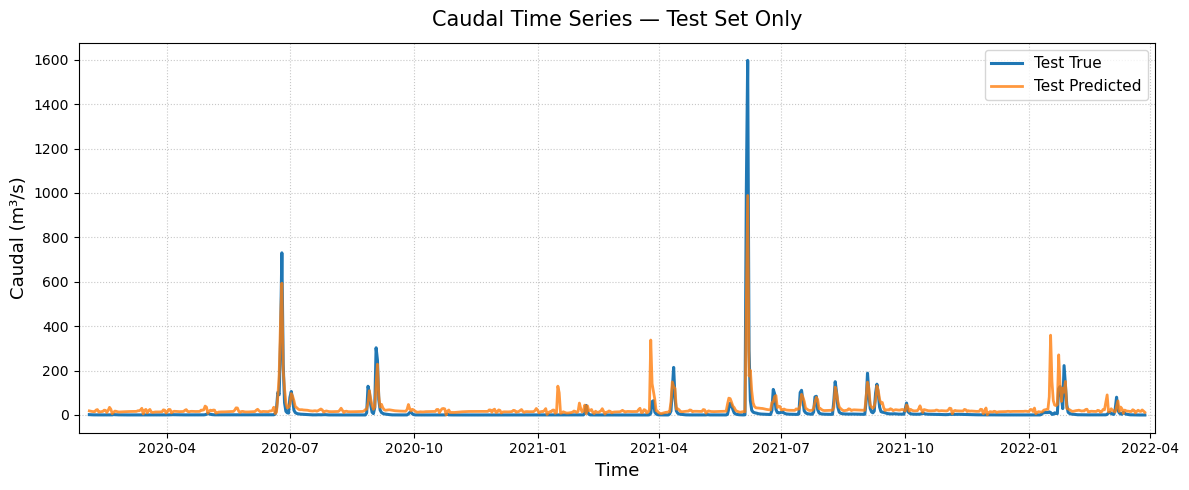

In [165]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_noweight.png')
plt.show()

## Graph

### Grafo 11

<img src="notebook_imgs/v4/grafo11.jpg" width="40%">

In [208]:
df_data_precip_all = pd.read_parquet(data_folder+"SLC_all_data_2011_2022.parquet")
df_data_precip_all = df_data_precip_all.drop(columns=["[Florida (Puente Ruta 5)] Nivel de agua (h) [m]"]) # Drop nivel (= Caudal)
df_data_precip_all

,[Florida (Puente Ruta 5)] Caudal (Q) [m3/s],[INIA Las Brujas] Evapotranspiracion Penman (ET) [mm],[INIA Las Brujas] Heliofania (Hel) [hs],[INIA Las Brujas] Humedad relativa media (HR) [%],[INIA Las Brujas] Radiacion solar (RS) [cal/cm2/dia],[INIA Las Brujas] Temperatura del aire media (TA) [ºC(24hs)],[INIA Las Brujas] Temperatura del aire maxima (TA) [ºC],[INIA Las Brujas] Temperatura del aire minima (TA) [ºC],[INIA Las Brujas] Velocidad del viento (VV) [2m/km/24h],[Cerro Colorado] Precipitacion (P) [mm],[La Cruz] Precipitacion (P) [mm],[Reboledo] Precipitacion (P) [mm],[San Gabriel] Precipitacion (P) [mm],[Sarandi Grande] Precipitacion (P) [mm]
date,,,,,,,,,,,,,,
2011-01-01,0.347,5.9,9.9,70.0,576.7,22.6,28.2,17.5,205.0,0.0,0.0,0.0,0.0,0.0
2011-01-02,0.333,5.9,9.3,72.0,555.6,23.2,29.4,18.4,223.4,0.0,1.5,0.0,0.0,0.0
2011-01-03,0.353,6.6,9.8,61.0,572.6,23.8,29.6,19.9,216.0,0.0,0.0,0.0,0.0,0.0
2011-01-04,0.383,3.9,2.2,72.0,308.1,23.0,28.2,18.9,165.9,0.0,0.0,0.0,0.0,0.0
2011-01-05,0.383,4.1,5.2,77.0,412.1,23.4,30.3,19.6,80.5,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2022-03-24,0.084,2.5,5.9,74.0,329.9,18.5,23.2,11.8,85.1,2.0,3.0,2.0,4.0,10.0
2022-03-25,0.062,1.5,2.8,92.0,239.1,13.9,18.6,11.2,112.2,3.0,5.0,3.0,6.0,7.0
2022-03-26,0.057,1.7,2.2,89.0,220.3,17.4,21.7,12.7,113.8,0.0,1.0,0.0,2.0,0.0


In [209]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_precip_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---
coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [210]:
# --- (2) Se define la conectividad del grafo ---

num_grafo="grafo11"

# Se incorpora un self loop
edge_index = torch.tensor([
    [2, 3, 4, 5, 6],
    [0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[2, 3, 4, 5, 6],
        [0, 0, 0, 0, 0]])

In [211]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_precip_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [212]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_precip_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [213]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_precip_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [214]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [215]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [216]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=False

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[7, 36, 10], edge_index=[2, 5], y=4.089299181941897e-05, edge_weight=[5, 1])
Length test: 785
Graph test: Data(x=[7, 36, 10], edge_index=[2, 5], y=0.0004632504715118557, edge_weight=[5, 1])


### Model

In [217]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [218]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = False

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_weigths.pth')
else:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_noweigths.pth')

Epoch [001/200] | Train Loss: 0.036604 | Train NSE: -21.64 | Test Loss: 0.000710 | Test NSE: -0.04
Epoch [002/200] | Train Loss: 0.001732 | Train NSE: -0.00 | Test Loss: 0.000543 | Test NSE: 0.01
Epoch [003/200] | Train Loss: 0.001206 | Train NSE: 0.25 | Test Loss: 0.000402 | Test NSE: 0.26
Epoch [004/200] | Train Loss: 0.000893 | Train NSE: 0.45 | Test Loss: 0.000442 | Test NSE: 0.19
Epoch [005/200] | Train Loss: 0.000787 | Train NSE: 0.51 | Test Loss: 0.000507 | Test NSE: 0.07
Epoch [006/200] | Train Loss: 0.000749 | Train NSE: 0.54 | Test Loss: 0.000541 | Test NSE: 0.01
Epoch [007/200] | Train Loss: 0.000722 | Train NSE: 0.56 | Test Loss: 0.000553 | Test NSE: -0.02
Epoch [008/200] | Train Loss: 0.000695 | Train NSE: 0.57 | Test Loss: 0.000563 | Test NSE: -0.04
Epoch [009/200] | Train Loss: 0.000667 | Train NSE: 0.59 | Test Loss: 0.000579 | Test NSE: -0.06
Epoch [010/200] | Train Loss: 0.000646 | Train NSE: 0.60 | Test Loss: 0.000598 | Test NSE: -0.10
Epoch [011/200] | Train Loss: 0.

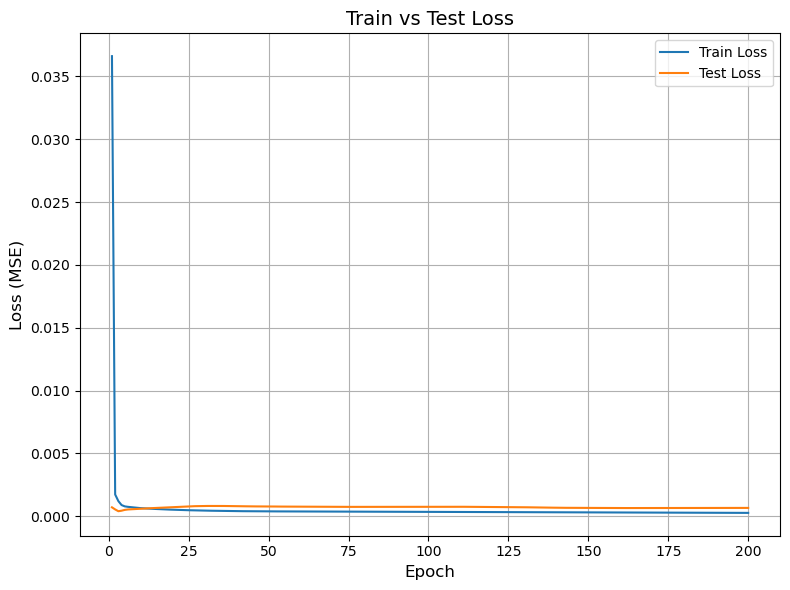

In [219]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/loss_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/loss_noweight.png')
plt.show()

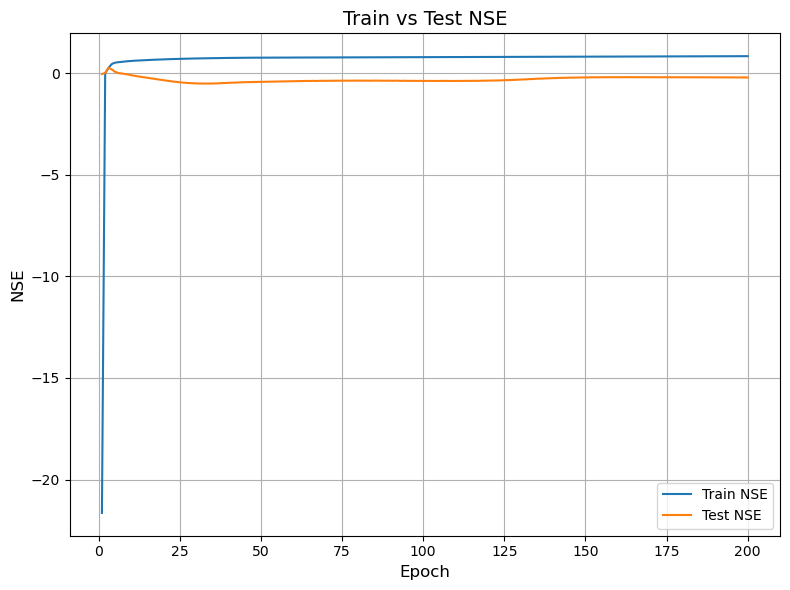

In [220]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/nse_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/nse_noweight.png')
plt.show()

In [221]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

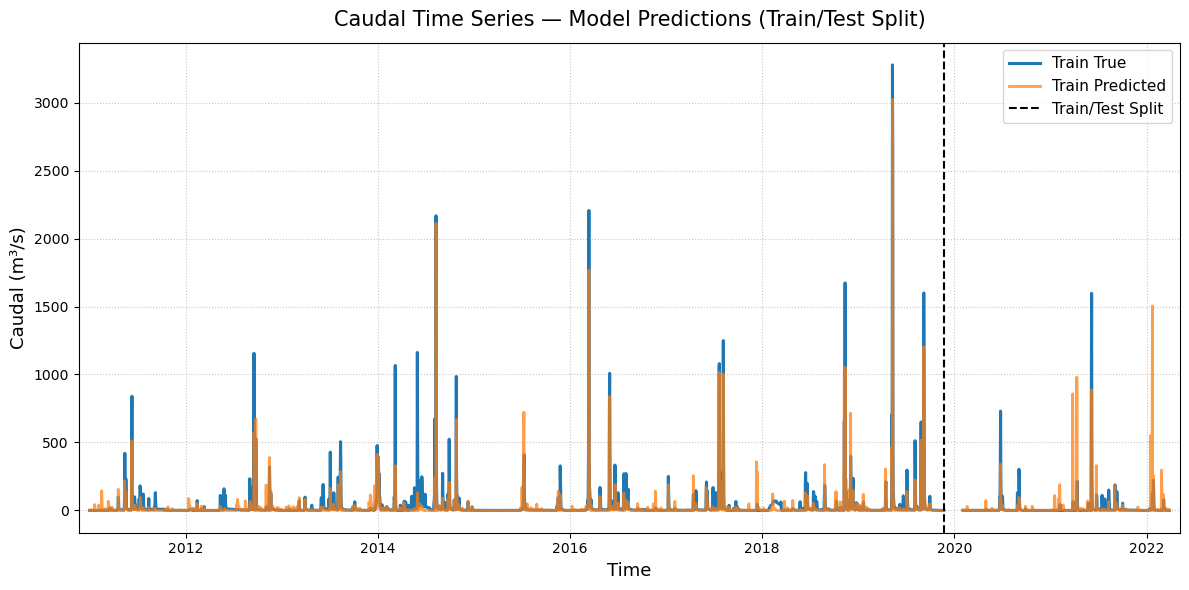

In [222]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_precip_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_precip_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_noweight.png')
plt.show()

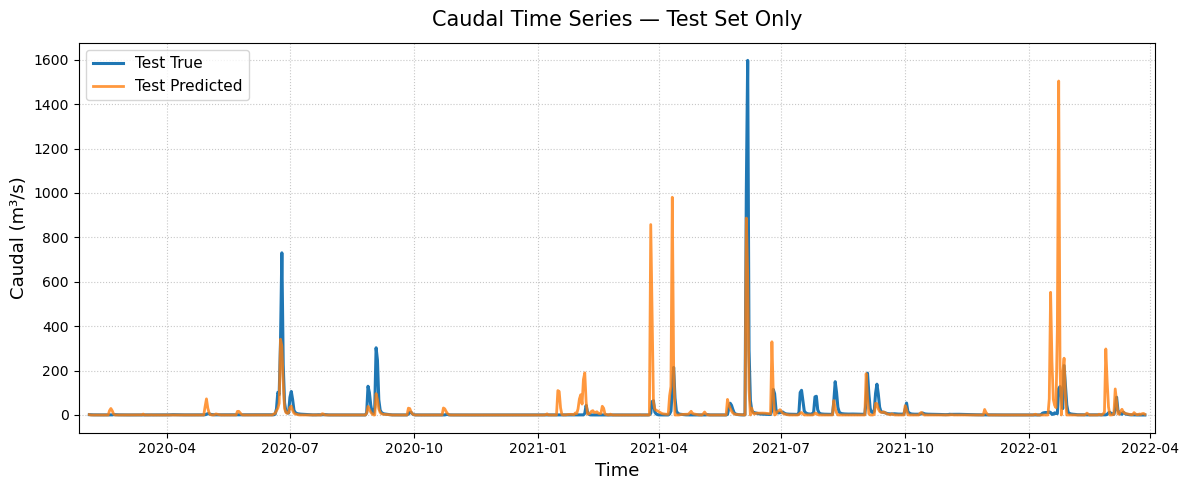

In [223]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_noweight.png')
plt.show()

## Graph

### Grafo 12

<img src="notebook_imgs/v4/grafo12.jpg" width="40%">

In [187]:
target_station = "Florida (Puente Ruta 5)"
target_variable = "Caudal (Q) [m3/s]"

all_cols = list(df_data_precip_all.columns)
all_stations = [
    re.search(r"\[(.*?)\]", e).group(1)
    for e in all_cols
]
station_order = list(dict.fromkeys(all_stations)) # Remove duplicates from list while preserving order of elements

stations_coords = pd.read_csv(data_folder+"other_data/SL_stations.csv")

stations_coords = stations_coords[stations_coords["station"].isin(station_order)] # Keep only stations inside Florida's basin
stations_coords = stations_coords.set_index('station') # Define new index

# --- (1) Se definen las distancias ---
coords_list = [
        (stations_coords.loc[s, 'longitud'],
        stations_coords.loc[s, 'latitud'])
    for s in station_order
]

target_station_coords = [stations_coords.loc[target_station, 'longitud'],
                            stations_coords.loc[target_station, 'latitud']]

In [188]:
# --- (2) Se define la conectividad del grafo ---

num_grafo="grafo12"

# Se incorpora un self loop
edge_index = torch.tensor([
    [0, 2, 3, 4, 5, 6],
    [0, 0, 0, 0, 0, 0]
], dtype=torch.long)
edge_index

tensor([[0, 2, 3, 4, 5, 6],
        [0, 0, 0, 0, 0, 0]])

In [189]:
from collections import defaultdict

def extract_station(col):
    return re.match(r"\[(.*?)\]", col).group(1)

station_columns = defaultdict(list)

for col in df_data_precip_all.columns:
    st = extract_station(col)
    station_columns[st].append(col)

In [190]:
def extract_variable(col):
    return re.sub(r"\[.*?\]\s*", "", col)

variable_order = [c.split("] ", 1)[1] for c in df_data_precip_all.columns]
variable_order = list(dict.fromkeys(variable_order))

In [191]:
from sklearn.model_selection import train_test_split

train_ratio = 0.8
test_ratio = 0.2

# First split: train vs (val + test)
df_train, df_test = train_test_split(
    df_data_precip_all,
    train_size=train_ratio,
    shuffle=False
)

print(f"N° train samples: {len(df_train.index)}")
print(f"N° test samples: {len(df_test.index)}")


N° train samples: 3284
N° test samples: 821


In [192]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

scalerX = MinMaxScaler()
scalerY = MinMaxScaler()

target_col = f"[{target_station}] {target_variable}"


df_train_scaled = df_train.copy()

X_train = df_train_scaled.drop(columns=[target_col])
y_train = df_train_scaled[[target_col]] 

# Fit scalers
X_train_scaled = scalerX.fit_transform(X_train)
y_train_scaled = scalerY.fit_transform(y_train)

# Assign back
df_train_scaled[X_train.columns] = X_train_scaled
df_train_scaled[target_col] = y_train_scaled


df_test_scaled = df_test.copy()

X_test = df_test_scaled.drop(columns=[target_col])
y_test = df_test_scaled[[target_col]]

# Transform only
X_test_scaled = scalerX.transform(X_test)
y_test_scaled = scalerY.transform(y_test)

# Assign back
df_test_scaled[X_test.columns] = X_test_scaled
df_test_scaled[target_col] = y_test_scaled

In [193]:
import torch
import numpy as np

num_nodes = len(station_order)
num_features = len(variable_order)
num_time_train = len(df_train_scaled)
num_time_test = len(df_test_scaled)

X_all_train = torch.zeros(
    (num_nodes, num_time_train, num_features),
    dtype=torch.float32
)

X_all_test = torch.zeros(
    (num_nodes, num_time_test, num_features),
    dtype=torch.float32
)

for i, station in enumerate(station_order):

    for j, variable in enumerate(variable_order):

        col_name = f"[{station}] {variable}"

        if col_name in df_train_scaled.columns:

            X_all_train[i, :, j] = torch.tensor(
                df_train_scaled[col_name].values,
                dtype=torch.float32
            )

            X_all_test[i, :, j] = torch.tensor(
                df_test_scaled[col_name].values,
                dtype=torch.float32
            )

        else:
            # missing variable at station
            X_all_train[i, :, j] = 0.0
            X_all_test[i, :, j] = 0.0

In [194]:
target_feature_idx = variable_order.index(target_variable) # Variable --> Feature
target_node_idx = station_order.index(target_station) # Station --> Node

dist_weight = calc_weights("IDW")

edge_weight = dist_weight/dist_weight.sum() # Distance normalization --> edge weights
window_size = 36

use_streamflow_as_input=True

dataset_train = build_windowed_graphs(
    X_all_train,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

dataset_test = build_windowed_graphs(
    X_all_test,
    edge_index,
    window=window_size,
    target_feature_idx=target_feature_idx,
    target_node_idx=target_node_idx,
    edge_weight=edge_weight,
    use_streamflow_as_input=use_streamflow_as_input
)

print(f"Length train: {len(dataset_train)}")
print(f"Graph train: {dataset_train[0]}")
print(f"Length test: {len(dataset_test)}")
print(f"Graph test: {dataset_test[0]}")

Length train: 3248
Graph train: Data(x=[7, 36, 10], edge_index=[2, 6], y=4.089299181941897e-05, edge_weight=[6, 1])
Length test: 785
Graph test: Data(x=[7, 36, 10], edge_index=[2, 6], y=0.0004632504715118557, edge_weight=[6, 1])


### Model

In [195]:
from torch_geometric.loader import DataLoader
batch_dize = 64

train_loader = DataLoader(dataset_train, batch_size=batch_dize, shuffle=False)
test_loader = DataLoader(dataset_test, batch_size=batch_dize, shuffle=False)

In [202]:
num_features = dataset_train[0]["x"].shape[2]

model = BasicGNN(
    num_features=num_features,
    gnn_hidden=16, 
    rnn_hidden=16,
    out_channels=1
)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)
criterion = nn.MSELoss()

num_epochs = 200

train_loss_list = []
test_loss_list = []
test_nse_list = []
train_nse_list = []

use_weigths = True

for epoch in range(num_epochs):
    loss, train_nse = train(model, criterion, optimizer, train_loader, use_weigths)
    test_loss, test_nse = test(model, criterion, test_loader, use_weigths)

    train_loss_list.append(loss)
    test_loss_list.append(test_loss)
    test_nse_list.append(test_nse)
    train_nse_list.append(train_nse)

    print(
        f"Epoch [{1+epoch:03d}/{num_epochs}] | "
        f"Train Loss: {loss:.6f} | "
        f"Train NSE: {train_nse:.2f} | "
        f"Test Loss: {test_loss:.6f} | "
        f"Test NSE: {test_nse:.2f}"
    )

if use_weigths:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_weigths.pth')
else:
    torch.save(model, f'v4/models/BasicGNN_{num_grafo}_noweigths.pth')

Epoch [001/200] | Train Loss: 0.001854 | Train NSE: -0.02 | Test Loss: 0.000675 | Test NSE: -0.22
Epoch [002/200] | Train Loss: 0.001599 | Train NSE: 0.01 | Test Loss: 0.000715 | Test NSE: -0.29
Epoch [003/200] | Train Loss: 0.001569 | Train NSE: 0.03 | Test Loss: 0.000704 | Test NSE: -0.27
Epoch [004/200] | Train Loss: 0.001515 | Train NSE: 0.06 | Test Loss: 0.000668 | Test NSE: -0.20
Epoch [005/200] | Train Loss: 0.001448 | Train NSE: 0.10 | Test Loss: 0.000614 | Test NSE: -0.11
Epoch [006/200] | Train Loss: 0.001368 | Train NSE: 0.15 | Test Loss: 0.000550 | Test NSE: 0.00
Epoch [007/200] | Train Loss: 0.001278 | Train NSE: 0.21 | Test Loss: 0.000485 | Test NSE: 0.12
Epoch [008/200] | Train Loss: 0.001186 | Train NSE: 0.26 | Test Loss: 0.000427 | Test NSE: 0.22
Epoch [009/200] | Train Loss: 0.001101 | Train NSE: 0.32 | Test Loss: 0.000386 | Test NSE: 0.29
Epoch [010/200] | Train Loss: 0.001026 | Train NSE: 0.36 | Test Loss: 0.000361 | Test NSE: 0.34
Epoch [011/200] | Train Loss: 0.00

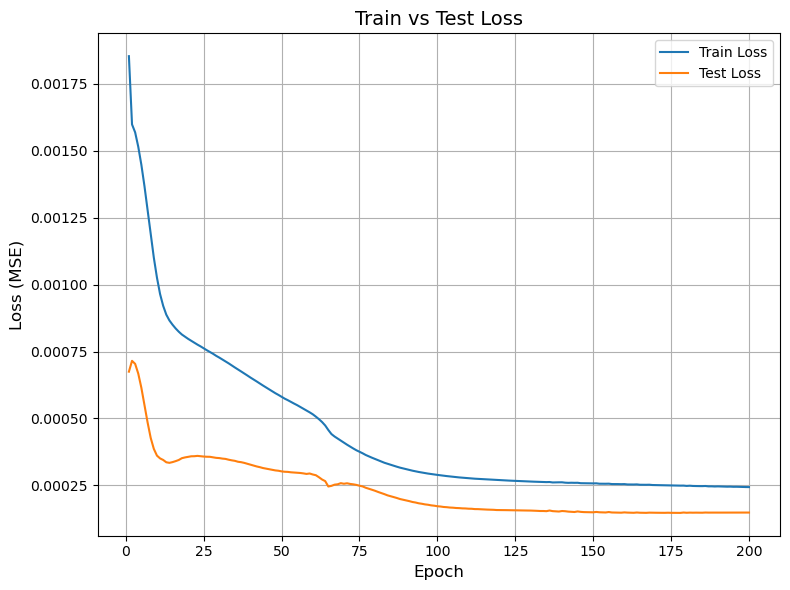

In [203]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_loss_list, label="Train Loss")
plt.plot(epochs, test_loss_list, label="Test Loss")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss (MSE)", fontsize=12)
plt.title("Train vs Test Loss", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/loss_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/loss_noweight.png')
plt.show()

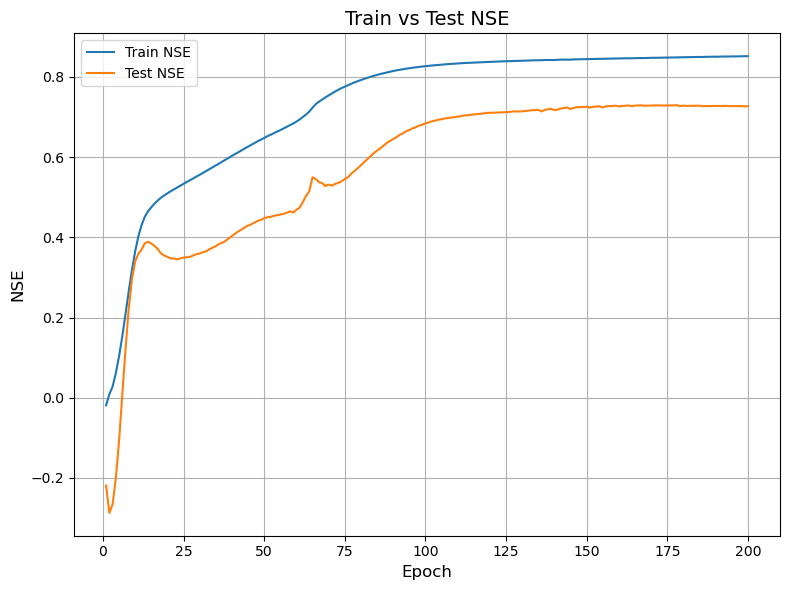

In [204]:
import matplotlib.pyplot as plt

epochs = range(1, num_epochs + 1)

plt.figure(figsize=(8,6))

plt.plot(epochs, train_nse_list, label="Train NSE")
plt.plot(epochs, test_nse_list, label="Test NSE")

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("NSE", fontsize=12)
plt.title("Train vs Test NSE", fontsize=14)
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)
#plt.ylim(-0.5)

plt.legend(fontsize=10)
plt.grid(True)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/nse_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/nse_noweight.png')
plt.show()

In [205]:
model.eval()

y_pred_train = []
y_pred_test = []

with torch.no_grad():

    for data in dataset_train:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)


        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_train.append(target_true_inv)

    for data in dataset_test:
        if use_weigths:
            out = model(data.x, data.edge_index, data.edge_weight)
        else:
            out = model(data.x, data.edge_index)

        pred = out[target_node_idx::num_nodes]

        target_true_inv = scalerY.inverse_transform(pred.reshape(-1, 1))
        target_true_inv[target_true_inv<0] = 0

        y_pred_test.append(target_true_inv)

y_pred_train = np.array(y_pred_train)
y_pred_test = np.array(y_pred_test)

# Combine predictions
y_pred = np.concatenate([
    y_pred_train,
    y_pred_test
])

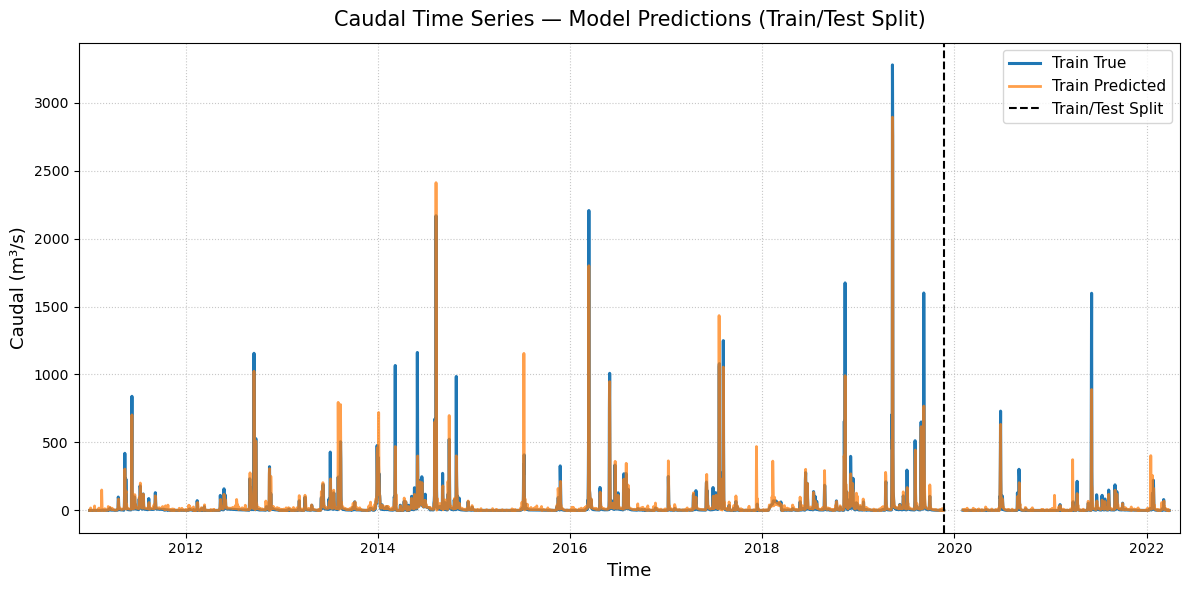

In [206]:
import numpy as np

# True values (NO SHUFFLE — keep temporal order)
y_true_all = df_data_precip_all.loc[:, target_col].values

split_index = int(len(y_true_all) * train_ratio)

y_true_train = y_true_all[:split_index]
y_true_test = y_true_all[split_index:]

# Remove window offset (VERY IMPORTANT)
y_true_train = y_true_train[window_size:]
y_true_test = y_true_test[window_size:]

samples_train = y_true_train.size
samples_test = y_true_test.size

y_pred_train = y_pred[:samples_train].squeeze()
y_pred_test = y_pred[samples_train:].squeeze()

time = df_data_precip_all.index

# --- Style settings
plt.figure(figsize=(12, 6))

# Colorblind-friendly colors
color_true = "#1f77b4"   # blue
color_pred = "#ff7f0e"   # orange

lw_true = 2.2
lw_pred = 2.0

# --- Training data (solid lines)

plt.plot(
    time[:samples_train],
    y_true_train,
    label="Train True",
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[:samples_train],
    y_pred_train,
    label="Train Predicted",
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75   # transparency helps overlap visibility
)

# --- Testing data (dashed lines)

plt.plot(
    time[-samples_test:],
    y_true_test,
    color=color_true,
    linewidth=lw_true,
    linestyle="-"
)

plt.plot(
    time[-samples_test:],
    y_pred_test,
    color=color_pred,
    linewidth=lw_pred,
    linestyle="-",
    alpha=0.75
)

# --- Divider line

plt.axvline(
    x=time[samples_train],
    linestyle="--",
    linewidth=1.5,
    color="black",
    label="Train/Test Split"
)

# --- Labels and formatting

plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.title(
    "Caudal Time Series — Model Predictions (Train/Test Split)",
    fontsize=15,
    pad=12
)

plt.legend(fontsize=11)

plt.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    alpha=0.7
)

plt.margins(x=0.01)

plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_noweight.png')
plt.show()

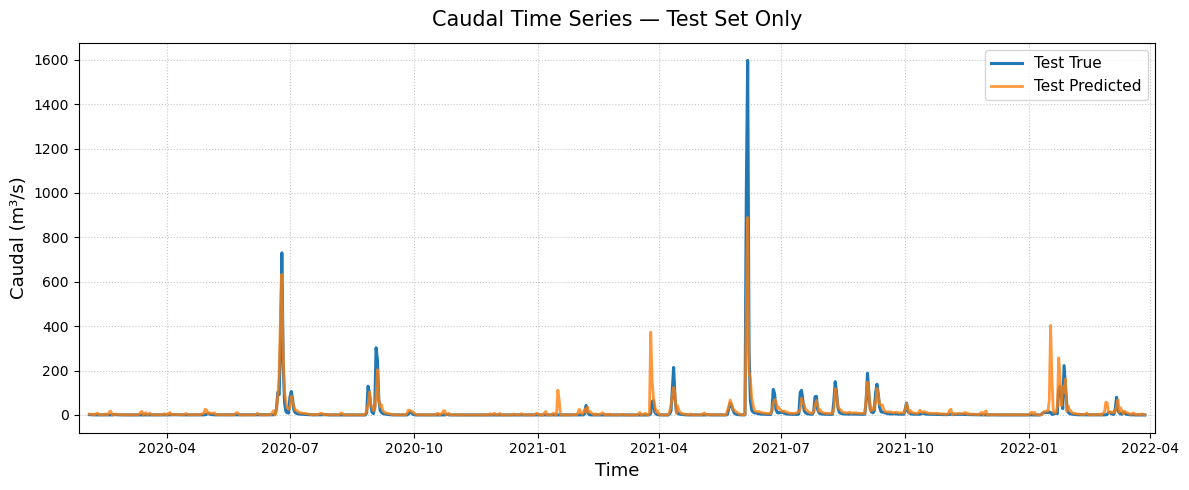

In [207]:
import matplotlib.pyplot as plt

# --- Test-only figure
plt.figure(figsize=(12, 5))

# Time for test segment
time_test = time[-samples_test:]

# True and predicted
plt.plot(
    time_test,
    y_true_test,
    label="Test True",
    color=color_true,
    linewidth=2.2
)

plt.plot(
    time_test,
    y_pred_test,
    label="Test Predicted",
    color=color_pred,
    linewidth=2.0,
    alpha=0.8
)

# Formatting
plt.title("Caudal Time Series — Test Set Only", fontsize=15, pad=12)
plt.xlabel("Time", fontsize=13)
plt.ylabel("Caudal (m³/s)", fontsize=13)

plt.grid(True, linestyle=":", alpha=0.7)
plt.legend(fontsize=11)

plt.margins(x=0.01)
plt.tight_layout()
if use_weigths:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_weight.png')
else:
    plt.savefig(f'v4/plots/{num_grafo}/caudal_test_noweight.png')
plt.show()